# What affects bike demand? Hypothesis tests

This notebook replaces `old/AB Testing.ipynb`. The old name was misleading: an A/B test randomly assigns a treatment, and nothing here was randomised. These are **observational comparisons**, so they show association, not cause. Section 4 goes a step further and estimates each weather effect with the main confounders held fixed.

| v1 | v2 | Why |
|---|---|---|
| One-sided hypothesis, two-sided p-value | One-sided test where the hypothesis is one-sided | The p-value should answer the question asked |
| p-values only | Effect sizes and confidence intervals | With thousands of hours, even a tiny difference is "significant" |
| Hours treated as independent | Confidence intervals that resample whole days; day-clustered errors | Hours on the same day move together, which makes naive p-values too small |
| ANOVA assumptions listed, not checked | Checked; Welch's ANOVA, Kruskal–Wallis and a post-hoc test added | Equal variances do not hold here |
| Chi-squared test on proportions (p = 1.0 whatever the data) | Day-level permutation test on hourly profiles | The old test could never reject |
| Snow and rain studied one at a time | Regression holding temperature, hour, humidity, weekend and season fixed | Snowy hours are also colder; rain falls more in summer |

In [1]:
try:
    import bikeshare  # noqa: F401
except ModuleNotFoundError:  # running without `pip install -e .`
    import sys
    sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats as st
from statsmodels.stats.oneway import anova_oneway

from bikeshare import data, plotting
from bikeshare import stats as bst

plotting.use_style()
hourly = data.load()
open_hours = hourly[hourly["functioning"]].copy()
print(f"{len(open_hours):,} open hours, {open_hours['date'].min():%d %b %Y} to {open_hours['date'].max():%d %b %Y}")

8,465 open hours, 01 Dec 2017 to 30 Nov 2018


## 1. Do winter hours with snowfall have fewer rentals?

Winter open hours only, split by whether any snowfall was recorded (> 0 cm).

- H0: mean hourly rentals are the same with and without snowfall.
- H1: mean hourly rentals are **lower** with snowfall (one-sided, the same hypothesis as v1).

In [2]:
winter = open_hours[open_hours["season"] == "Winter"].copy()
winter["snow"] = winter["snowfall"] > 0
clear, snowy = winter.loc[~winter["snow"], "rentals"], winter.loc[winter["snow"], "rentals"]
names = {False: "no snowfall", True: "snowfall"}
summary = winter.groupby("snow").agg(hours=("rentals", "size"), days=("date", "nunique"), mean=("rentals", "mean"),
                                     median=("rentals", "median"), temperature=("temperature", "mean"),
                                     humidity=("humidity", "mean"))
summary.rename(index=names).round(1)

,hours,days,mean,median,temperature,humidity
snow,,,,,,
no snowfall,1768,82,240.7,223.0,-1.9,47.4
snowfall,392,24,157.3,142.0,-5.4,60.2


Snowy hours are also much colder and more humid, so part of the gap may be the cold rather than the snow. Section 4 separates the two.

In [3]:
levene = st.levene(clear, snowy)
welch = st.ttest_ind(clear, snowy, equal_var=False, alternative="greater")
mann_whitney = st.mannwhitneyu(clear, snowy, alternative="greater")
g = bst.hedges_g(clear, snowy)
diff, ci = bst.cluster_bootstrap_diff(winter["rentals"], ~winter["snow"], winter["date"], n_boot=10_000)
naive_ci = st.ttest_ind(clear, snowy, equal_var=False).confidence_interval()
pd.Series({
    "Levene p-value (equal variances?)": f"{levene.pvalue:.1e}  -> variances differ, so Welch's test",
    "Welch t statistic": f"{welch.statistic:.2f}",
    "Welch p-value, one-sided": f"{welch.pvalue:.1e}",
    "Mann-Whitney p-value, one-sided": f"{mann_whitney.pvalue:.1e}",
    "difference in means": f"{diff:.0f} bikes per hour ({1 - snowy.mean() / clear.mean():.0%} fewer with snowfall)",
    "95% CI, hours treated as independent": f"{naive_ci.low:.0f} to {naive_ci.high:.0f}",
    "95% CI, resampling whole days": f"{ci[0]:.0f} to {ci[1]:.0f}",
    "Hedges' g (effect size)": f"{g:.2f}",
}, name="result").to_frame()

,result
Levene p-value (equal variances?),"1.1e-12 -> variances differ, so Welch's test"
Welch t statistic,12.59
"Welch p-value, one-sided",1.7e-33
"Mann-Whitney p-value, one-sided",3.0e-27
difference in means,83 bikes per hour (35% fewer with snowfall)
"95% CI, hours treated as independent",70 to 96
"95% CI, resampling whole days",59 to 107
Hedges' g (effect size),0.57


Snowy winter hours average 157 rentals, against 241 without snow: 83 fewer, or 35%. Welch's one-sided test gives p = 1.7 × 10⁻³³. v1 reported the two-sided value (3.3 × 10⁻³³) for a one-sided hypothesis. The rank-based Mann–Whitney test agrees. The effect size is medium (Hedges' g = 0.57).

Treating hours as independent understates the uncertainty. Snowfall was recorded on only 24 days, and hours within a day are alike. Resampling whole days widens the 95% interval from 70–96 to 59–107 bikes per hour, which is still clearly above zero.

## 2. Does demand fall as rain gets heavier?

Rainy open hours only (rainfall > 0), split into four groups of roughly equal size (quartiles) by the amount of rain in the hour.

- H0: mean hourly rentals are the same in all four quartiles.
- H1: at least one quartile mean differs.

In [4]:
rainy = open_hours[open_hours["rainfall"] > 0].copy()
quartile_labels = ["Q1 lightest", "Q2", "Q3", "Q4 heaviest"]
rainy["quartile"], edges = pd.qcut(rainy["rainfall"], 4, labels=quartile_labels, retbins=True)
groups = {q: g["rentals"].to_numpy() for q, g in rainy.groupby("quartile", observed=True)}
rain_table = rainy.groupby("quartile", observed=True).agg(
    hours=("rentals", "size"), days=("date", "nunique"), rain_min_mm=("rainfall", "min"),
    rain_max_mm=("rainfall", "max"), mean=("rentals", "mean"), sd=("rentals", "std"))
rain_table.round(1)

,hours,days,rain_min_mm,rain_max_mm,mean,sd
quartile,,,,,,
Q1 lightest,203,83,0.1,0.5,251.4,325.7
Q2,71,40,0.7,1.0,145.6,225.2
Q3,118,50,1.1,2.5,112.1,182.4
Q4 heaviest,124,43,3.0,35.0,94.4,191.5


In [5]:
tests = {
    "one-way ANOVA (as in v1)": st.f_oneway(*groups.values()),
    "Welch's ANOVA (unequal variances)": anova_oneway(list(groups.values()), use_var="unequal"),
    "Kruskal-Wallis (rank-based)": st.kruskal(*groups.values()),
    "Levene (are variances equal?)": st.levene(*groups.values()),
}
print(f"eta squared: {bst.eta_squared(groups.values()):.3f} of the variation in rentals is explained by rain quartile")
pd.DataFrame({"statistic": [t.statistic for t in tests.values()], "p-value": [t.pvalue for t in tests.values()]},
             index=list(tests)).map(lambda v: f"{v:.3g}")

eta squared: 0.069 of the variation in rentals is explained by rain quartile


,statistic,p-value
one-way ANOVA (as in v1),12.7,4.94e-08
Welch's ANOVA (unequal variances),11.1,7.62e-07
Kruskal-Wallis (rank-based),109,1.97e-23
Levene (are variances equal?),6.24,0.000365


In [6]:
games_howell = bst.games_howell(groups)
games_howell.round({"mean_diff": 1, "t": 2, "df": 1, "p_adj": 4})

,group_a,group_b,mean_diff,t,df,p_adj
0,Q1 lightest,Q2,105.8,3.01,177.1,0.0158
1,Q1 lightest,Q3,139.4,4.91,318.6,0.0000
2,Q1 lightest,Q4 heaviest,157.0,5.49,324.6,0.0000
3,Q2,Q3,33.6,1.06,124.6,0.7121
4,Q2,Q4 heaviest,51.2,1.61,127.6,0.3753
5,Q3,Q4 heaviest,17.7,0.73,240.0,0.8830


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


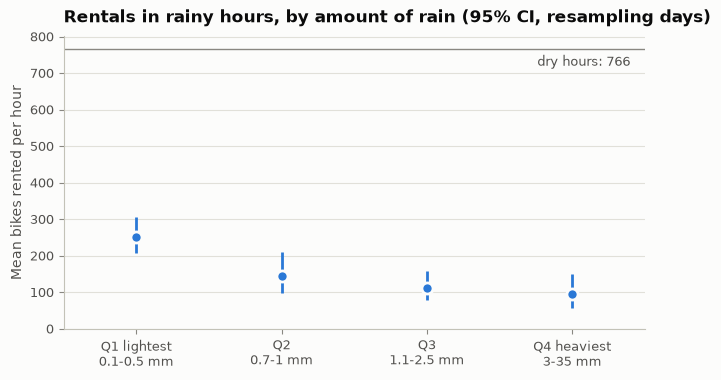

In [7]:
rows = []
for q, g in rainy.groupby("quartile", observed=True):
    mean, (low, high) = bst.cluster_bootstrap_mean(g["rentals"], g["date"])
    rows.append({"quartile": q, "mean": mean, "low": low, "high": high})
means = pd.DataFrame(rows).set_index("quartile")
dry_mean = open_hours.loc[open_hours["rainfall"] == 0, "rentals"].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(means))
ax.errorbar(x, means["mean"], yerr=[means["mean"] - means["low"], means["high"] - means["mean"]], fmt="o", color=plotting.BLUE, markersize=8, capsize=0,
            elinewidth=2, markeredgecolor=plotting.SURFACE, markeredgewidth=2)
ax.axhline(dry_mean, color=plotting.MUTED, linewidth=1)
ax.annotate(f"dry hours: {dry_mean:.0f}", (len(means) - 0.6, dry_mean), xytext=(0, -12), textcoords="offset points",
            ha="right", fontsize=9, color=plotting.INK_2)
ax.set_xticks(x, [f"{q}\n{lo:g}-{hi:g} mm" for q, lo, hi in zip(means.index, rain_table["rain_min_mm"],
                                                                  rain_table["rain_max_mm"])])
ax.set_xlim(-0.5, len(means) - 0.5)
ax.set_ylim(bottom=0)
ax.set_ylabel("Mean bikes rented per hour")
ax.set_title("Rentals in rainy hours, by amount of rain (95% CI, resampling days)")
plotting.save(fig, "rain_quartiles")
plt.show()

All three tests reject equal means (Welch's ANOVA p = 7.6 × 10⁻⁷, Kruskal–Wallis p = 2 × 10⁻²³). Levene's test confirms the variances differ, which v1's ANOVA assumed away. The effect is modest: rain quartile explains 7% of the variation in rentals across rainy hours. (The quartiles are not exactly equal in size because many hours share the same rainfall value.)

The Games–Howell post-hoc test shows *where* the difference lies: only the lightest rain (0.1–0.5 mm) differs from the rest. From 0.7 mm upward, demand is similarly low (94 to 146 per hour) and the three heavier quartiles cannot be told apart. In practice, drizzle puts off some riders and anything heavier puts off most. Even drizzle hours are far below dry hours (766 per hour), but dry hours also differ in season and time of day, so section 4 accounts for that.

## 3. Do spring and summer have the same daily rhythm?

v1 asked whether the average hourly profiles of summer and spring differ, using a chi-squared test. It ran the test on proportions that sum to 1 instead of on counts, which makes the statistic close to 0 whatever the data, so it returned p = 1.0 and could never reject.

The question is about the *shape* of the day (when people ride), not the level. Each day open for all 24 hours becomes a profile: the share of that day's rentals falling in each hour.

- **Effect size:** the total variation distance (TVD) between the average spring and summer profiles, the share of rides that would have to move to a different hour to turn one profile into the other.
- **Test:** shuffle the season labels across days 10,000 times and count how often a TVD at least this large appears by chance. Shuffling whole days keeps each day's hours together.

In [8]:
full_days = open_hours.groupby("date").filter(lambda d: len(d) == 24)
profiles = full_days.pivot(index="date", columns="hour", values="rentals")
profiles = profiles.div(profiles.sum(axis=1), axis=0)
season_of_day = full_days.groupby("date")["season"].first().astype(str)
keep = season_of_day.isin(["Spring", "Summer"])
tvd, p_value, null = bst.permutation_test_profiles(profiles[keep], season_of_day[keep], n_perm=10_000)
print(f"{(season_of_day[keep] == 'Spring').sum()} spring days, {(season_of_day[keep] == 'Summer').sum()} summer days")
print(f"TVD = {tvd:.1%} of rides | permutation p-value = {p_value:.4f} | 95th percentile under H0 = {np.percentile(null, 95):.1%}")

counts = full_days[full_days["season"].isin(["Spring", "Summer"])].pivot_table(
    index="hour", columns="season", values="rentals", aggfunc="sum", observed=True)
chi2 = st.chi2_contingency(counts.to_numpy())
cramers_v = np.sqrt(chi2.statistic / (counts.to_numpy().sum() * (min(counts.shape) - 1)))
print(f"for comparison, chi-squared on total ride counts: p = {chi2.pvalue:.1g}, Cramer's V = {cramers_v:.3f} "
      f"(treats each of {counts.to_numpy().sum():,} rides as independent)")

90 spring days, 92 summer days
TVD = 10.7% of rides | permutation p-value = 0.0001 | 95th percentile under H0 = 4.5%
for comparison, chi-squared on total ride counts: p = 0, Cramer's V = 0.112 (treats each of 3,895,143 rides as independent)


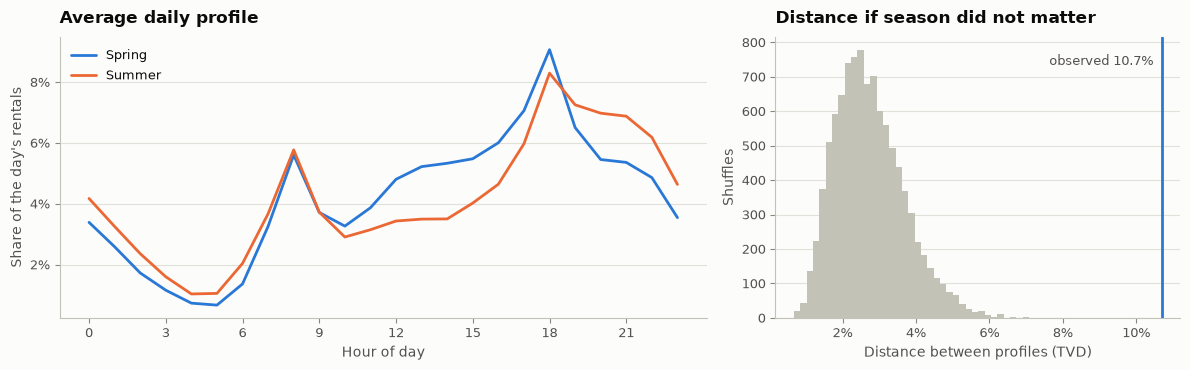

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for season, color in [("Spring", plotting.BLUE), ("Summer", plotting.ORANGE)]:
    profile = profiles[season_of_day == season].mean()
    axes[0].plot(profile.index, profile.values, color=color, label=season)
axes[0].yaxis.set_major_formatter(plotting.percent)
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Share of the day's rentals")
axes[0].set_title("Average daily profile")
axes[0].legend(loc="upper left")
axes[1].hist(null, bins=40, color=plotting.CONTEXT)
axes[1].axvline(tvd, color=plotting.BLUE, linewidth=2)
axes[1].annotate(f"observed {tvd:.1%}", (tvd, axes[1].get_ylim()[1] * 0.9), xytext=(-6, 0),
                 textcoords="offset points", ha="right", fontsize=9, color=plotting.INK_2)
axes[1].xaxis.set_major_formatter(plotting.percent)
axes[1].set_xlabel("Distance between profiles (TVD)")
axes[1].set_ylabel("Shuffles")
axes[1].set_title("Distance if season did not matter")
fig.tight_layout()
plotting.save(fig, "spring_vs_summer_profile")
plt.show()

The profiles clearly differ. About 11% of rides would have to move to another hour to turn the spring profile into the summer one, which is more than twice the 95th percentile of the shuffled distances (4.5%). None of the 10,000 shuffles got that far (p < 0.001). Summer moves riding out of the afternoon and into the evening (19:00 to 23:00), when it is cooler.

The chi-squared test on counts also rejects (p ≈ 0), but it treats 3.9 million rides as independent, so its p-value says little. The permutation test respects that rides on the same day are linked.

## 4. Weather effects with confounders held fixed

Sections 1 and 2 compare raw averages. But snowy hours are also colder and more humid, and rain falls more in summer, when demand is high anyway. Poisson regressions estimate each weather effect while holding other factors fixed.

Each coefficient becomes a **rate ratio**: 0.70 means 30% fewer rentals than in otherwise similar hours. Poisson regression estimates the mean correctly even when counts are more spread out than Poisson, as long as the standard errors are robust; here they are clustered by day. It is still observational: anything left out of the model (an event in the city, say) can bias it.

**4a. Snow (winter hours only).** Snow only falls in winter, so the snow model uses winter hours and adds controls one step at a time, to show how much of the raw gap each confounder explains.

In [10]:
reg = open_hours.copy()
reg["snowing"] = (reg["snowfall"] > 0).astype(int)
reg["raining"] = (reg["rainfall"] > 0).astype(int)
reg["rain"] = pd.cut(reg["rainfall"], bins=[-np.inf, 0, *edges[1:-1], np.inf], labels=["none", *quartile_labels])
reg["hour_week"] = reg["hour"].astype(str) + np.where(reg["date"].dt.weekday >= 5, " weekend", " weekday")
reg["temperature_sq"] = reg["temperature"] ** 2
reg["temp_bin"] = pd.cut(reg["temperature"], bins=np.arange(-20, 42, 2)).astype(str)
reg["holiday_flag"] = reg["holiday"].astype(int)
percent_format = {"change in rentals": "{:+.0%}", "95% CI low": "{:+.0%}", "95% CI high": "{:+.0%}",
                  "p-value": "{:.1e}"}


def effects(formula, frame, terms):
    """Poisson regression with day-clustered errors; % change in rentals for each term."""
    fit = smf.glm(formula, data=frame, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(frame["date"])[0]})
    conf = np.exp(fit.conf_int().loc[terms]) - 1
    table = pd.DataFrame({"change in rentals": np.exp(fit.params[terms]) - 1, "95% CI low": conf[0],
                          "95% CI high": conf[1], "p-value": fit.pvalues[terms]})
    return table, fit


winter_reg = reg[reg["season"] == "Winter"]
snow_steps = {
    "raw gap": "rentals ~ snowing",
    "+ hour of day (weekday / weekend)": "rentals ~ snowing + C(hour_week)",
    "+ temperature": "rentals ~ snowing + C(hour_week) + temperature + temperature_sq",
    "+ humidity, wind, rain, holiday": "rentals ~ snowing + C(hour_week) + temperature + temperature_sq"
                                       " + humidity + wind_speed + raining + holiday_flag",
    "same, but without humidity": "rentals ~ snowing + C(hour_week) + temperature + temperature_sq"
                                  " + wind_speed + raining + holiday_flag",
}
snow_effects = pd.concat([effects(f, winter_reg, ["snowing"])[0].rename(index={"snowing": name})
                          for name, f in snow_steps.items()])
snow_effects.style.format(percent_format)

,change in rentals,95% CI low,95% CI high,p-value
raw gap,-35%,-43%,-25%,3.1e-10
+ hour of day (weekday / weekend),-34%,-43%,-24%,3.7e-09
+ temperature,-28%,-36%,-18%,8.7e-07
"+ humidity, wind, rain, holiday",-19%,-28%,-7%,1.6e-03
"same, but without humidity",-25%,-34%,-15%,7.1e-06


Adding controls shrinks the snow effect step by step: -35% raw, -34% after time of day, -28% after temperature, and -19% after humidity, wind, rain and holidays (95% CI -28% to -7%). Snow still matters, but about half of the raw gap is really the cold and humidity that come with it. Humidity rises when it snows, so holding humidity fixed may also remove part of the genuine snow effect; without humidity the estimate is -25%. A fair summary: snowfall cuts winter demand by roughly a fifth to a quarter, not by a third.

**4b. Rain (all open hours).** Rain falls in every season, so this model uses the whole year with flexible controls: a separate weekday and weekend daily profile for each season, temperature in 2 °C bands, humidity, wind, snowfall and holidays.

In [11]:
rain_formula = ("rentals ~ rain + snowing + C(hour_week):season + C(temp_bin) + humidity + wind_speed"
                " + holiday_flag")
rain_terms = {f"rain[T.{q}]": f"rain {q}" for q in quartile_labels}
rain_effects, rain_fit = effects(rain_formula, reg, list(rain_terms))
without_humidity, _ = effects(rain_formula.replace(" + humidity", ""), reg, list(rain_terms))
rain_effects["without humidity"] = without_humidity["change in rentals"]
rain_effects = rain_effects.rename(index=rain_terms)
print(f"deviance explained: {1 - rain_fit.deviance / rain_fit.null_deviance:.1%}")
rain_effects.style.format({**percent_format, "without humidity": "{:+.0%}"})

deviance explained: 89.6%


,change in rentals,95% CI low,95% CI high,p-value,without humidity
rain Q1 lightest,-63%,-70%,-56%,1.3e-26,-70%
rain Q2,-80%,-87%,-71%,3.6e-16,-85%
rain Q3,-84%,-89%,-77%,1.3e-23,-88%
rain Q4 heaviest,-88%,-93%,-80%,2.3e-15,-91%


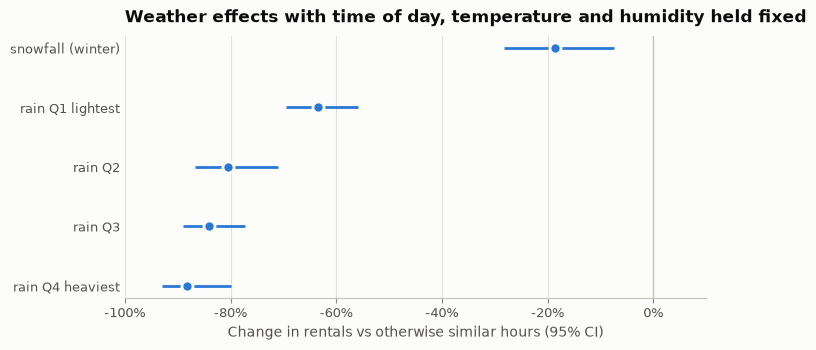

In [12]:
forest = pd.concat([snow_effects.loc[["+ humidity, wind, rain, holiday"]].rename(
    index={"+ humidity, wind, rain, holiday": "snowfall (winter)"}), rain_effects])
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y_pos = np.arange(len(forest))[::-1]
ax.errorbar(forest["change in rentals"], y_pos,
            xerr=[forest["change in rentals"] - forest["95% CI low"],
                  forest["95% CI high"] - forest["change in rentals"]],
            fmt="o", color=plotting.BLUE, markersize=8, elinewidth=2, capsize=0, markeredgecolor=plotting.SURFACE,
            markeredgewidth=2)
ax.axvline(0, color=plotting.AXIS, linewidth=1)
ax.set_yticks(y_pos, forest.index)
ax.xaxis.set_major_formatter(plotting.percent)
ax.set_xlim(-1, 0.1)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Change in rentals vs otherwise similar hours (95% CI)")
ax.set_title("Weather effects with time of day, temperature and humidity held fixed")
plotting.save(fig, "weather_effects")
plt.show()

Rain has a far larger effect than snow, and the effect grows with intensity: -63% in the lightest quartile, then -80%, -84% and -88%, holding time of day, season, temperature and humidity fixed. Without humidity, the effects are a few points larger (-70% to -91%). The model explains 90% of the deviance. Unlike the raw comparison in section 2, the regression does separate drizzle from heavier rain and shows each heavier quartile slightly lower, though their intervals overlap.

## Summary

| Question | v1 answer | v2 answer |
|---|---|---|
| Fewer rentals in snowy winter hours? | Yes (p < 0.001) | Yes: 35% fewer in raw terms, about 19 to 25% once temperature, humidity and time of day are held fixed |
| Does demand differ with rain intensity? | Yes (p < 0.001) | Yes, but mainly drizzle vs the rest. With controls, rain cuts demand by 63% (drizzle) to 88% (heavy rain) |
| Do spring and summer have the same hourly profile? | Yes (p = 1.0, from a test that could not reject) | No: about 11% of rides shift hours (p < 0.001), towards the cooler evening |

These are associations in observational data, not proof of cause, although section 4 removes the most obvious confounders.